In [19]:
# ============================================================
# ANDROID PRIVACY PROJECT
# PRECISION + CoV VISUALIZATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. LOAD EXCEL FILE
# ------------------------------------------------------------

file_path = "Precision_CoV_Comparision.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Precision CoV Comparison"
)

# ------------------------------------------------------------
# 2. DEFINE CATEGORIES AND CLASSIFIERS
# ------------------------------------------------------------

categories = [
    "Games",
    "Lifestyle & Health",
    "Entertainment & Media",
    "Productivity & Tools",
    "Education & Reference",
    "Social & Communication"
]

classifiers = [
    "Decision Tree",
    "Random Forest",
    "AdaBoost",
    "SVM"
]

# ------------------------------------------------------------
# 3. EXTRACT BORDA + GARRETT DATA
# ------------------------------------------------------------

# First 4 classifier rows are Borda + Garrett
bg = df.iloc[1:5].copy()

bg = bg.set_index("Metric")

bg = bg[classifiers if False else categories]

# Rename index to make sure it is clean
bg.index.name = "Classifier"

# ------------------------------------------------------------
# 4. EXTRACT ML DATA
# ------------------------------------------------------------

ml_start = df.index[
    df["Metric"] == "ML (Basic Classifiers)"
][0]

ml = df.iloc[
    ml_start + 1 : ml_start + 5
].copy()

ml = ml.set_index("Metric")

ml = ml[categories]

ml.index.name = "Classifier"

# ------------------------------------------------------------
# 5. CONVERT EVERYTHING TO NUMERIC
# ------------------------------------------------------------

bg = bg.apply(pd.to_numeric, errors="coerce")
ml = ml.apply(pd.to_numeric, errors="coerce")

# ------------------------------------------------------------
# 6. CHECK DATA
# ------------------------------------------------------------

print("=" * 60)
print("BORDA + GARRETT PRECISION")
print("=" * 60)
print(bg.round(4))

print("\n")

print("=" * 60)
print("ML PRECISION")
print("=" * 60)
print(ml.round(4))

BORDA + GARRETT PRECISION
                Games  Lifestyle & Health  Entertainment & Media  \
Classifier                                                         
Decision Tree  0.8799              0.9760                 0.8514   
Random Forest  0.8923              0.9773                 0.8855   
AdaBoost       0.7571              0.8582                 0.7948   
SVM            0.8237              0.9123                 0.8468   

               Productivity & Tools  Education & Reference  \
Classifier                                                   
Decision Tree                0.9009                 0.9485   
Random Forest                0.8700                 0.9748   
AdaBoost                     0.7356                 0.8472   
SVM                          0.8217                 0.9250   

               Social & Communication  
Classifier                             
Decision Tree                  0.8680  
Random Forest                  0.8737  
AdaBoost                       0

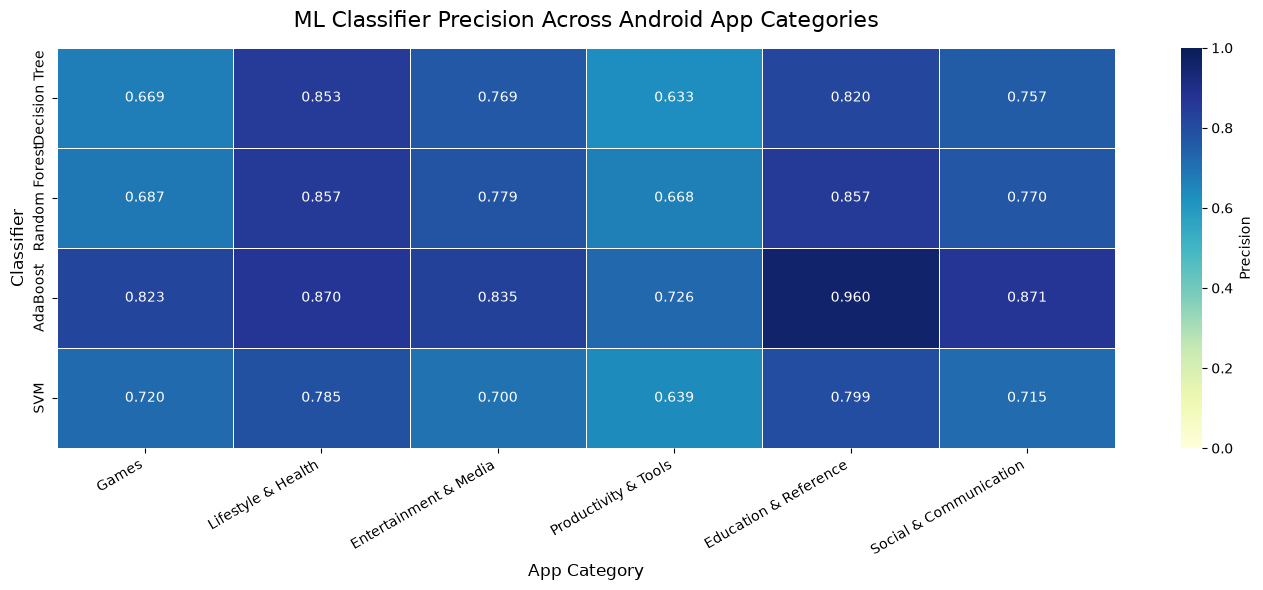

In [20]:
# ============================================================
# GRAPH 1
# ML PRECISION HEATMAP
# ============================================================

plt.figure(figsize=(14, 6))

sns.heatmap(
    ml,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={
        "label": "Precision"
    }
)

plt.title(
    "ML Classifier Precision Across Android App Categories",
    fontsize=16,
    pad=15
)

plt.xlabel(
    "App Category",
    fontsize=12
)

plt.ylabel(
    "Classifier",
    fontsize=12
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "01_ML_Precision_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

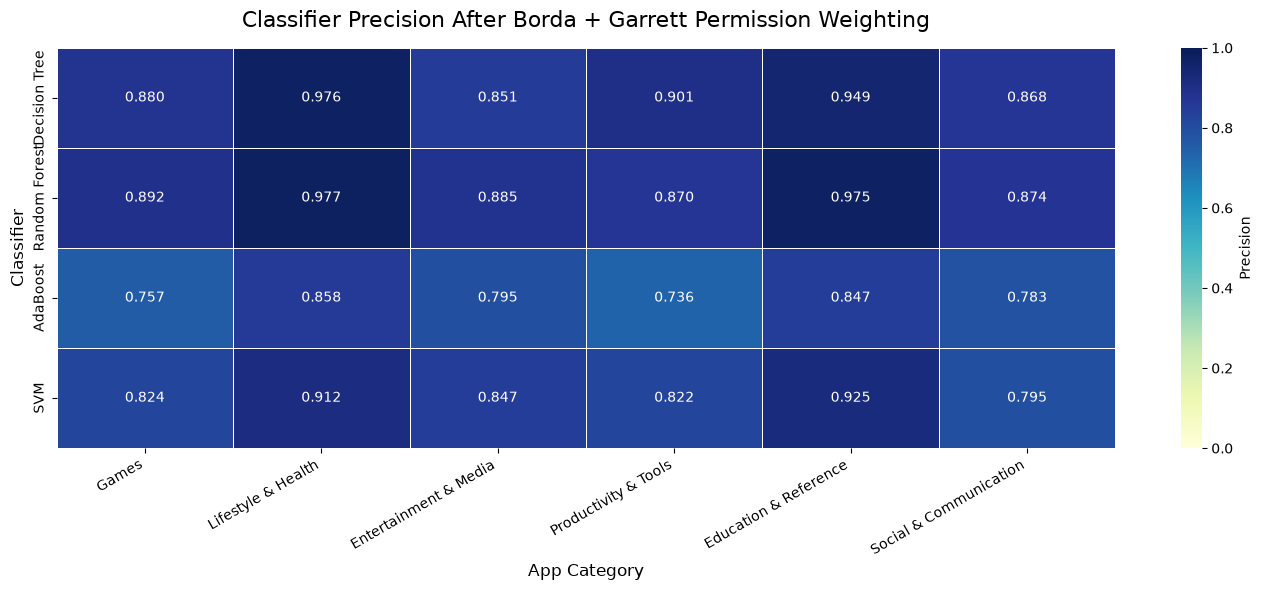

In [21]:
# ============================================================
# GRAPH 2
# BORDA + GARRETT PRECISION HEATMAP
# ============================================================

plt.figure(figsize=(14, 6))

sns.heatmap(
    bg,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={
        "label": "Precision"
    }
)

plt.title(
    "Classifier Precision After Borda + Garrett Permission Weighting",
    fontsize=16,
    pad=15
)

plt.xlabel(
    "App Category",
    fontsize=12
)

plt.ylabel(
    "Classifier",
    fontsize=12
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "02_Borda_Garrett_Precision_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Mean Precision Comparison:
                            ML  Borda + Garrett
Games                   0.7249           0.8382
Lifestyle & Health      0.8413           0.9310
Entertainment & Media   0.7705           0.8446
Productivity & Tools    0.6663           0.8320
Education & Reference   0.8591           0.9239
Social & Communication  0.7784           0.8297


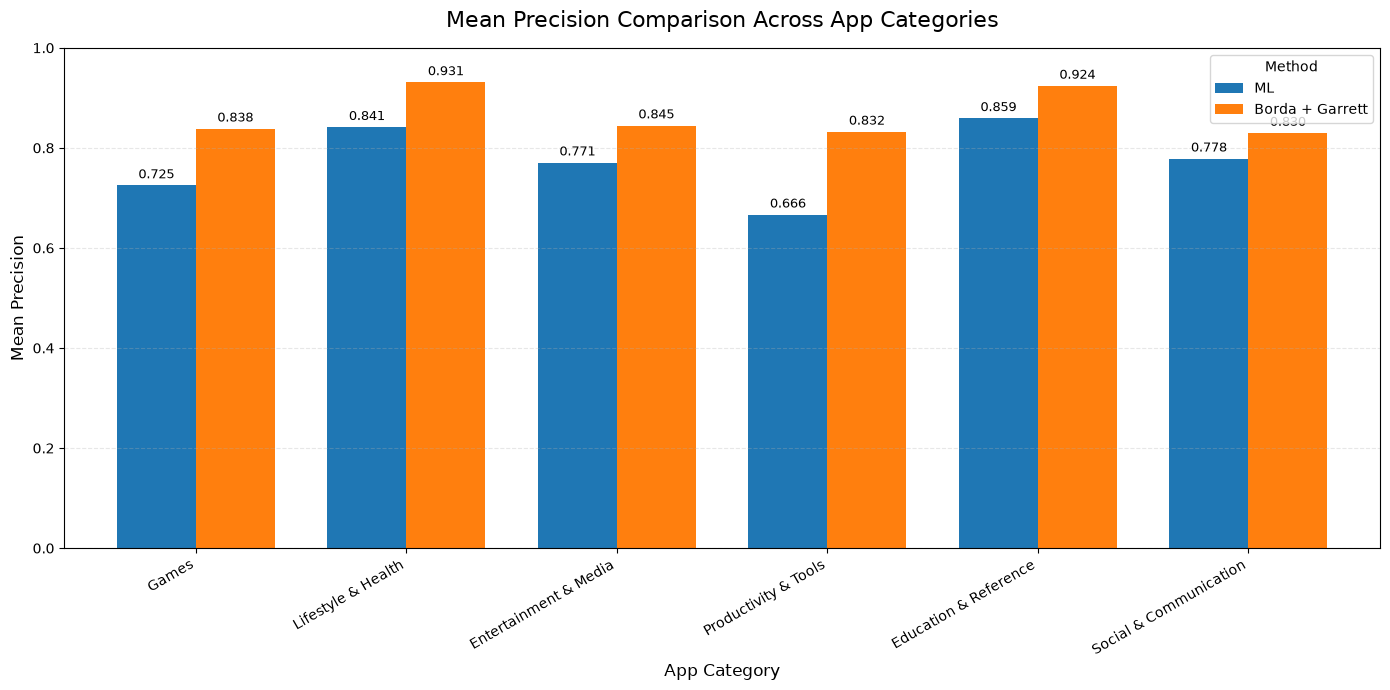

In [23]:
# ============================================================
# GRAPH 3
# MEAN PRECISION COMPARISON
# ============================================================

ml_mean = ml.mean(axis=0)

bg_mean = bg.mean(axis=0)

mean_comparison = pd.DataFrame({
    "ML": ml_mean,
    "Borda + Garrett": bg_mean
})

print("\nMean Precision Comparison:")
print(mean_comparison.round(4))


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

ax = mean_comparison.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.75
)

plt.title(
    "Mean Precision Comparison Across App Categories",
    fontsize=16,
    pad=15
)

plt.xlabel(
    "App Category",
    fontsize=12
)

plt.ylabel(
    "Mean Precision",
    fontsize=12
)

plt.ylim(0, 1)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.legend(
    title="Method"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Add values on top of bars
for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "03_Mean_Precision_ML_vs_Borda_Garrett.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

C:\Users\Dhruvi\AppData\Local\Temp\ipykernel_9368\409727139.py:181: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


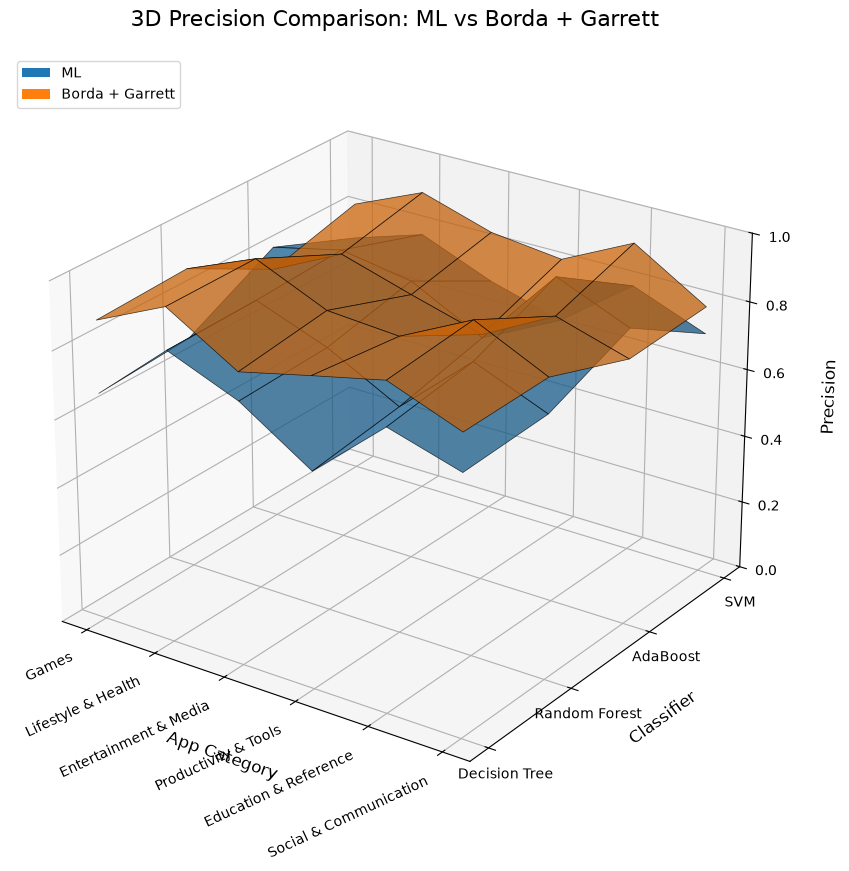

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ============================================================
# LOAD DATA
# ============================================================

file_path = "Precision_CoV_Comparision.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Precision CoV Comparison"
)

categories = [
    "Games",
    "Lifestyle & Health",
    "Entertainment & Media",
    "Productivity & Tools",
    "Education & Reference",
    "Social & Communication"
]

classifiers = [
    "Decision Tree",
    "Random Forest",
    "AdaBoost",
    "SVM"
]

# ============================================================
# EXTRACT BORDA + GARRETT
# ============================================================

bg = df.iloc[1:5].copy()
bg = bg.set_index("Metric")[categories]
bg = bg.astype(float)

# ============================================================
# EXTRACT ML
# ============================================================

ml_start = df.index[
    df["Metric"] == "ML (Basic Classifiers)"
][0]

ml = df.iloc[
    ml_start + 1:ml_start + 5
].copy()

ml = ml.set_index("Metric")[categories]
ml = ml.astype(float)

# ============================================================
# CREATE NUMERIC GRID
# ============================================================

X, Y = np.meshgrid(
    np.arange(len(categories)),
    np.arange(len(classifiers))
)

Z_ml = ml.values
Z_bg = bg.values

# ============================================================
# PLOT
# ============================================================

fig = plt.figure(figsize=(16, 10))

ax = fig.add_subplot(
    111,
    projection="3d"
)

# ------------------------------------------------------------
# ML SURFACE
# ------------------------------------------------------------

surface1 = ax.plot_surface(
    X,
    Y,
    Z_ml,
    alpha=0.75,
    linewidth=0.5,
    edgecolor="black"
)

# ------------------------------------------------------------
# BORDA + GARRETT SURFACE
# ------------------------------------------------------------

surface2 = ax.plot_surface(
    X,
    Y,
    Z_bg,
    alpha=0.75,
    linewidth=0.5,
    edgecolor="black"
)

# ============================================================
# AXES
# ============================================================

ax.set_xlabel(
    "App Category",
    labelpad=15,
    fontsize=12
)

ax.set_ylabel(
    "Classifier",
    labelpad=15,
    fontsize=12
)

ax.set_zlabel(
    "Precision",
    labelpad=15,
    fontsize=12
)

ax.set_xticks(
    np.arange(len(categories))
)

ax.set_xticklabels(
    categories,
    rotation=25,
    ha="right"
)

ax.set_yticks(
    np.arange(len(classifiers))
)

ax.set_yticklabels(
    classifiers
)

ax.set_zlim(0, 1)

# Better viewing angle
ax.view_init(
    elev=25,
    azim=-55
)

ax.set_title(
    "3D Precision Comparison: ML vs Borda + Garrett",
    fontsize=16,
    pad=20
)

# ============================================================
# LEGEND
# ============================================================

from matplotlib.patches import Patch

legend_elements = [
    Patch(
        facecolor="C0",
        label="ML"
    ),
    Patch(
        facecolor="C1",
        label="Borda + Garrett"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "3D_Precision_Surface_ML_vs_BG.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

ML Mean Precision:
Games                     0.7249
Lifestyle & Health        0.8413
Entertainment & Media     0.7705
Productivity & Tools      0.6663
Education & Reference     0.8591
Social & Communication    0.7784
dtype: float64

Borda + Garrett Mean Precision:
Games                     0.8382
Lifestyle & Health        0.9310
Entertainment & Media     0.8446
Productivity & Tools      0.8320
Education & Reference     0.9239
Social & Communication    0.8297
dtype: float64


C:\Users\Dhruvi\AppData\Local\Temp\ipykernel_9368\3258966584.py:175: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


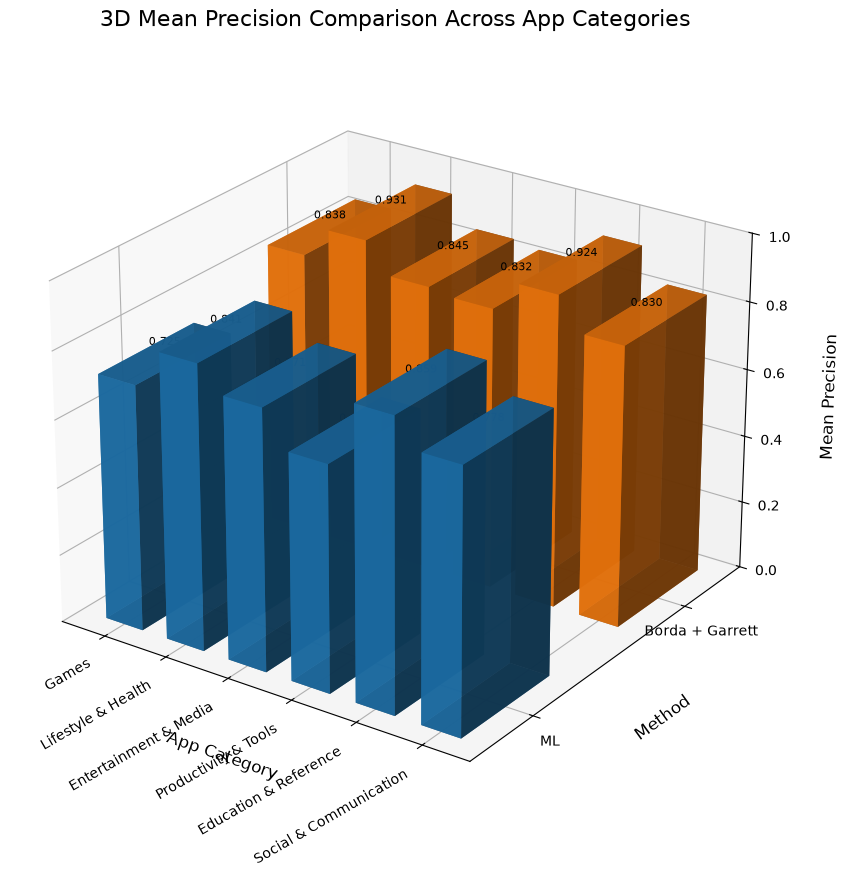

In [25]:
# ============================================================
# 3D GRAPH 2
# CATEGORY × METHOD × MEAN PRECISION
# ============================================================

# ------------------------------------------------------------
# CALCULATE MEAN PRECISION
# ------------------------------------------------------------

ml_mean = ml.mean(axis=0)
bg_mean = bg.mean(axis=0)

print("ML Mean Precision:")
print(ml_mean.round(4))

print("\nBorda + Garrett Mean Precision:")
print(bg_mean.round(4))


# ============================================================
# CREATE 3D BAR GRAPH
# ============================================================

fig = plt.figure(figsize=(16, 10))

ax = fig.add_subplot(
    111,
    projection="3d"
)

# ------------------------------------------------------------
# POSITIONS
# ------------------------------------------------------------

x = np.arange(len(categories))

# Method positions
y_ml = np.zeros(len(categories))
y_bg = np.ones(len(categories))

# Bar dimensions
dx = 0.6
dy = 0.55


# ------------------------------------------------------------
# ML BARS
# ------------------------------------------------------------

ax.bar3d(
    x,
    y_ml,
    np.zeros(len(categories)),
    dx,
    dy,
    ml_mean.values,
    shade=True,
    alpha=0.85
)


# ------------------------------------------------------------
# BORDA + GARRETT BARS
# ------------------------------------------------------------

ax.bar3d(
    x,
    y_bg,
    np.zeros(len(categories)),
    dx,
    dy,
    bg_mean.values,
    shade=True,
    alpha=0.85
)


# ============================================================
# AXES
# ============================================================

ax.set_xlabel(
    "App Category",
    labelpad=15,
    fontsize=12
)

ax.set_ylabel(
    "Method",
    labelpad=15,
    fontsize=12
)

ax.set_zlabel(
    "Mean Precision",
    labelpad=15,
    fontsize=12
)


# X-axis
ax.set_xticks(
    x + dx / 2
)

ax.set_xticklabels(
    categories,
    rotation=30,
    ha="right"
)


# Y-axis
ax.set_yticks(
    [dy / 2, 1 + dy / 2]
)

ax.set_yticklabels(
    [
        "ML",
        "Borda + Garrett"
    ]
)


# Z-axis
ax.set_zlim(
    0,
    1
)


# ============================================================
# VIEW
# ============================================================

ax.view_init(
    elev=25,
    azim=-55
)


ax.set_title(
    "3D Mean Precision Comparison Across App Categories",
    fontsize=16,
    pad=20
)


# ============================================================
# ADD VALUES ON TOP OF BARS
# ============================================================

for i in range(len(categories)):

    ax.text(
        i + dx / 2,
        dy / 2,
        ml_mean.iloc[i] + 0.025,
        f"{ml_mean.iloc[i]:.3f}",
        ha="center",
        fontsize=8
    )

    ax.text(
        i + dx / 2,
        1 + dy / 2,
        bg_mean.iloc[i] + 0.025,
        f"{bg_mean.iloc[i]:.3f}",
        ha="center",
        fontsize=8
    )


plt.tight_layout()

plt.savefig(
    "3D_Mean_Precision_ML_vs_BG.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()